In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv


In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv")
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.shape

(7043, 21)

In [5]:
df.info()
df['Churn'].value_counts()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [6]:
# TotalCharges ne number ma convert karo
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# kya ane ketla khali che?
print(df['TotalCharges'].isna().sum())
print(df[df['TotalCharges'].isna()][['tenure']].head())

11
      tenure
488        0
753        0
936        0
1082       0
1340       0


In [7]:
# khali TotalCharges ne 0 karo
df['TotalCharges'] = df['TotalCharges'].fillna(0)

# duplicates check
print("Duplicates:", df.duplicated().sum())

# Churn ne number ma convert karo (Yes = 1, No = 0)
df['Churn_flag'] = (df['Churn'] == 'Yes').astype(int)

# check
print(df['TotalCharges'].isna().sum())
print(df['Churn_flag'].value_counts())

Duplicates: 0
0
Churn_flag
0    5174
1    1869
Name: count, dtype: int64


In [8]:
print(round(df['Churn_flag'].mean() * 100, 2), "%")

26.54 %


In [9]:
for col in ['Contract', 'InternetService', 'PaymentMethod']:
    print(df.groupby(col)['Churn_flag'].mean().mul(100).round(1), "\n")

Contract
Month-to-month    42.7
One year          11.3
Two year           2.8
Name: Churn_flag, dtype: float64 

InternetService
DSL            19.0
Fiber optic    41.9
No              7.4
Name: Churn_flag, dtype: float64 

PaymentMethod
Bank transfer (automatic)    16.7
Credit card (automatic)      15.2
Electronic check             45.3
Mailed check                 19.1
Name: Churn_flag, dtype: float64 



In [11]:
df['tenure_group'] = pd.cut(df['tenure'], [-1, 12, 24, 48, 72],
                            labels=['0-12', '13-24', '25-48', '49-72'])
print(df.groupby('tenure_group')['Churn_flag'].mean().mul(100).round(1))

tenure_group
0-12     47.4
13-24    28.7
25-48    20.4
49-72     9.5
Name: Churn_flag, dtype: float64


/tmp/ipykernel_49/2136443954.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(df.groupby('tenure_group')['Churn_flag'].mean().mul(100).round(1))


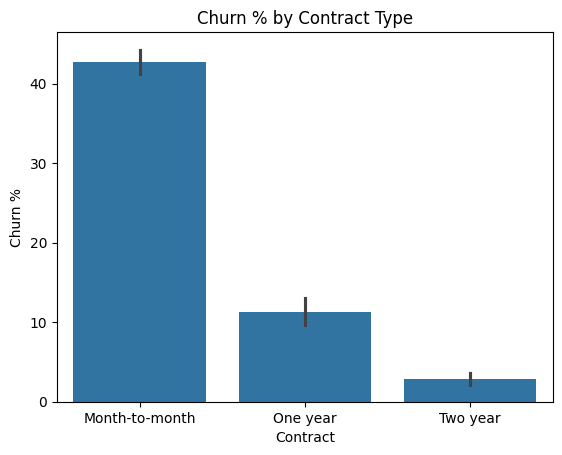

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.barplot(data=df, x='Contract', y='Churn_flag', estimator=lambda x: x.mean()*100)
plt.title("Churn % by Contract Type")
plt.ylabel("Churn %")
plt.show()

In [4]:
from scipy.stats import chi2_contingency

for col in ['Contract', 'InternetService', 'PaymentMethod', 'PaperlessBilling']:
    table = pd.crosstab(df[col], df['Churn'])
    chi2, p, dof, exp = chi2_contingency(table)
    print(col, "| p-value =", p)

Contract | p-value = 5.863038300673391e-258
InternetService | p-value = 9.571788222840544e-160
PaymentMethod | p-value = 3.6823546520097993e-140
PaperlessBilling | p-value = 4.073354668665985e-58


In [5]:
from scipy.stats import ttest_ind

churned = df[df['Churn'] == 'Yes']['MonthlyCharges']
stayed = df[df['Churn'] == 'No']['MonthlyCharges']

print("Churned avg:", round(churned.mean(), 2))
print("Stayed avg:", round(stayed.mean(), 2))
print("p-value:", ttest_ind(churned, stayed).pvalue)

Churned avg: 74.44
Stayed avg: 61.27
p-value: 2.7066456068884154e-60


In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

X = df.drop(columns=['customerID', 'Churn', 'Churn_flag', 'tenure_group'])
X = pd.get_dummies(X, drop_first=True)
y = df['Churn_flag']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

model = LogisticRegression(max_iter=1000)
model.fit(X_train_s, y_train)

print("Accuracy:", round(model.score(X_test_s, y_test), 3))

coef = pd.Series(model.coef_[0], index=X.columns).sort_values()
print(coef.head(5))   # churn ghatadva vala factors
print(coef.tail(5))   # churn vadharva vala factors

Accuracy: 0.82
tenure               -1.347355
MonthlyCharges       -0.628014
Contract_Two year    -0.613702
Contract_One year    -0.268336
OnlineSecurity_Yes   -0.158642
dtype: float64
MultipleLines_Yes              0.168199
StreamingTV_Yes                0.179380
StreamingMovies_Yes            0.228714
InternetService_Fiber optic    0.619853
TotalCharges                   0.649427
dtype: float64


In [7]:
risk = df[(df['Contract'] == 'Month-to-month') & (df['tenure'] <= 12)]

print("Customers:", len(risk))
print("Churn rate:", round(risk['Churn_flag'].mean() * 100, 1), "%")
print("Share of all churned customers:",
      round(risk['Churn_flag'].sum() / df['Churn_flag'].sum() * 100, 1), "%")

Customers: 1994
Churn rate: 51.4 %
Share of all churned customers: 54.8 %


Accuracy: 0.82


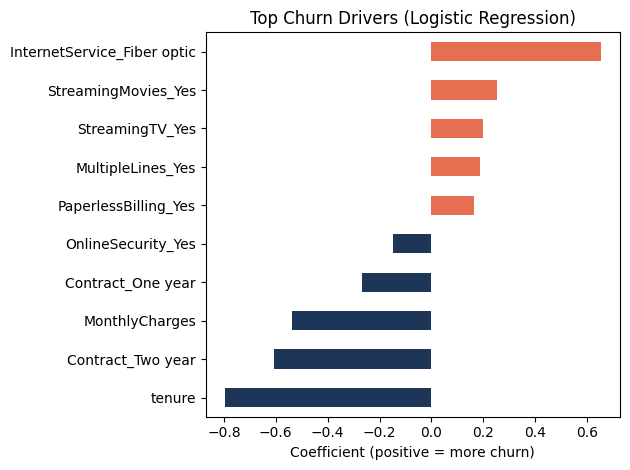

In [10]:
X2 = df.drop(columns=['customerID', 'Churn', 'Churn_flag', 'tenure_group', 'TotalCharges'])
X2 = pd.get_dummies(X2, drop_first=True)
y = df['Churn_flag']

X_train, X_test, y_train, y_test = train_test_split(X2, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

model = LogisticRegression(max_iter=1000)
model.fit(X_train_s, y_train)
print("Accuracy:", round(model.score(X_test_s, y_test), 3))

coef = pd.Series(model.coef_[0], index=X2.columns)
top = pd.concat([coef.sort_values().head(5), coef.sort_values().tail(5)])
top.plot(kind='barh', color=['#e76f51' if v > 0 else '#1d3557' for v in top])
plt.title("Top Churn Drivers (Logistic Regression)")
plt.xlabel("Coefficient (positive = more churn)")
plt.tight_layout()
plt.show()

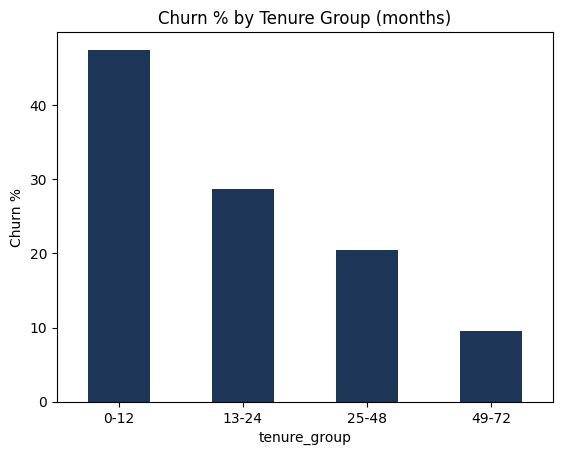

In [11]:
churn_by_tenure = df.groupby('tenure_group', observed=False)['Churn_flag'].mean() * 100
churn_by_tenure.plot(kind='bar', color='#1d3557')
plt.title("Churn % by Tenure Group (months)")
plt.ylabel("Churn %")
plt.xticks(rotation=0)
plt.show()